# Market Regime — nqstats  (Python recreation)

Standalone recreation of the **"Market Regime — nqstats"** Pine v6 indicator.
The Pine version runs its whole calculation on the **daily** timeframe
(`request.security(..., "D", ...)`) whatever the chart timeframe is — so this
notebook resamples your 1-min CSV to daily bars, then reproduces the four
rolling quantities per lookback.

| Pine cell | column | meaning |
|---|---|---|
| ROLLSD | `sd_L`     | rolling stdev of daily returns over `L` bars |
| RATIO / STATE | `ratio_L` | `sd / baseSD`  (>1 = *Elevated*, ≤1 = *Compressed*) |
| %ILE | `pctile_L` | percentile of the current stdev vs its own `trailLen` history |
| COMPR | `compr_L` | `ratio − ratio[trendWin]`  → *BUILD* (vol contracting) / *EASE* / *HOLD* |
| OVERALL | `overall` | driven by the L2 trend → COMPRESSING / STABLE / EXPANDING |

Faithful-to-Pine details: `ta.stdev` is the **population** (biased) stdev → `ddof=0`;
`ta.percentrank(sd, N)` = % of the previous `N` values ≤ the current one;
`trailLen = max(30, round(baseYears·252))`.

**Data loading matches the fractal notebook** — same `Date`+`Time` parse and the
same 18:00→17:00 ET session-anchored trading day. Edit the config cell and run
top to bottom.

In [7]:
# ═══════════════════════════════════════════════════════════════════════
# CONFIG  — same style as the fractal notebook
# ═══════════════════════════════════════════════════════════════════════
import os
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

# ── where the raw 1-min file lives, and what it is called ──────────────────
DATA_DIR      = r"C:\Users\tammm\NQ and ES analysis"
FILE_TEMPLATE = '{symbol}_15y_1min.csv'
SYMBOL        = 'ES'
FILE_PATH     = os.path.join(DATA_DIR, FILE_TEMPLATE.format(symbol=SYMBOL))

# Fallback: if that path isn't there, look for the file next to this notebook.
if not os.path.isfile(FILE_PATH):
    _local = FILE_TEMPLATE.format(symbol=SYMBOL)
    if os.path.isfile(_local):
        FILE_PATH = _local

# Load the FULL history: the baseline needs ~2520 daily bars to warm up, so
# unlike the fractal study we do NOT truncate the start here.
START_DATE = None
END_DATE   = None

# ── indicator inputs (mirror the Pine "input" defaults) ────────────────────
USE_LOG              = True          # log returns vs simple returns
LOOKBACKS            = (10, 20, 50)  # L1, L2, L3  (in daily bars)
BASELINE_YEARS       = 10.0          # baseline lookback in years
TREND_WINDOW         = 5             # trend window (days) for the ratio change
TREND_THRESHOLD      = 0.05          # deadband for BUILD/EASE and OVERALL
BARS_PER_YEAR        = 252           # trailLen = max(30, round(BASELINE_YEARS*BARS_PER_YEAR))
SESSION_ANCHOR_HOURS = 18            # daily bar anchor in ET; None = calendar day

AS_OF = None   # None = latest bar; or a date string like '2024-06-03'

print('reading:', FILE_PATH)

reading: C:\Users\tammm\NQ and ES analysis\ES_15y_1min.csv


In [8]:
# ═══════════════════════════════════════════════════════════════════════
# DATA  — 1-min CSV -> session-anchored daily OHLC (matches the fractal load)
# ═══════════════════════════════════════════════════════════════════════
def load_daily(path=FILE_PATH, start=START_DATE, end=END_DATE,
               anchor_hours=SESSION_ANCHOR_HOURS):
    df = pd.read_csv(path)
    df['Datetime'] = pd.to_datetime(df['Date'] + ' ' + df['Time'],
                                    format='%Y-%m-%d %H:%M:%S')
    df = df.set_index('Datetime').sort_index()
    if start is not None or end is not None:
        df = df.loc[start:end]

    agg = {'Open': 'first', 'High': 'max', 'Low': 'min', 'Close': 'last'}
    if anchor_hours:                      # 18:00 -> 17:00 ET trading day
        off = pd.Timedelta(hours=anchor_hours)
        shifted = df[list(agg)].copy()
        shifted.index = shifted.index - off
        daily = (shifted.resample('1D', label='left', closed='left')
                        .agg(agg).dropna(subset=['Open']))
        daily.index = daily.index + off
    else:                                 # plain calendar day
        daily = (df[list(agg)].resample('1D', label='left', closed='left')
                              .agg(agg).dropna(subset=['Open']))
    return daily

In [9]:
# ═══════════════════════════════════════════════════════════════════════
# PINE PRIMITIVES + REGIME CALCULATION
# ═══════════════════════════════════════════════════════════════════════
def _rolling_std(s, length):
    """ta.stdev(source, length): population (biased) stdev -> ddof=0."""
    return s.rolling(length, min_periods=length).std(ddof=0)

def _percentrank(s, length):
    """ta.percentrank(source, length): % of the previous `length` values that
    are <= the current value. NaNs in the window don't count (NaN<=x is False),
    and the denominator stays `length` — matching Pine."""
    v = s.to_numpy(dtype=float)
    out = np.full(len(v), np.nan)
    for i in range(length, len(v)):
        cur = v[i]
        if np.isnan(cur):
            continue
        out[i] = np.sum(v[i - length:i] <= cur) / length * 100.0
    return pd.Series(out, index=s.index)

def compute_regime(daily,
                   use_log=USE_LOG, lookbacks=LOOKBACKS,
                   baseline_years=BASELINE_YEARS, trend_window=TREND_WINDOW,
                   trend_threshold=TREND_THRESHOLD, bars_per_year=BARS_PER_YEAR):
    close = daily['Close']
    ret = np.log(close / close.shift(1)) if use_log else close / close.shift(1) - 1.0
    trail_len = max(30, round(baseline_years * bars_per_year))
    base_sd = _rolling_std(ret, trail_len)

    out = pd.DataFrame(index=daily.index)
    out['base_sd'] = base_sd
    for L in lookbacks:
        sd = _rolling_std(ret, L)
        q  = sd / base_sd.replace(0, np.nan)
        p  = _percentrank(sd, trail_len)
        tr = q - q.shift(trend_window)
        out[f'sd_{L}']     = sd
        out[f'ratio_{L}']  = q
        out[f'pctile_{L}'] = p
        out[f'trend_{L}']  = tr
        out[f'state_{L}']  = np.where(q.isna(), '--',
                             np.where(q > 1.0, 'Elevated', 'Compressed'))
        out[f'compr_{L}']  = np.where(tr.isna(), '--',
                             np.where(tr < -trend_threshold, 'BUILD',
                             np.where(tr >  trend_threshold, 'EASE', 'HOLD')))
    L2 = lookbacks[1]                     # OVERALL follows the 2nd lookback's trend
    t2 = out[f'trend_{L2}']
    out['overall'] = np.where(t2.isna(), '--',
                     np.where(t2 < -trend_threshold, 'COMPRESSING',
                     np.where(t2 >  trend_threshold, 'EXPANDING', 'STABLE')))
    out.attrs.update(lookbacks=tuple(lookbacks), trail_len=trail_len,
                     trend_threshold=trend_threshold)
    return out

def regime_table(regime, when=None):
    """Reproduce the indicator's on-chart table for one bar (default latest)."""
    lookbacks = regime.attrs['lookbacks']; trail_len = regime.attrs['trail_len']
    row = regime.iloc[-1] if when is None else regime.loc[when]
    if isinstance(row, pd.DataFrame):
        row = row.iloc[-1]
    pct = lambda x: '--' if pd.isna(x) else f'{round(x)}%'
    num = lambda x, n: '--' if pd.isna(x) else f'{x:.{n}f}'
    rows = [{'LOOKBACK': f'{L}d', 'STATE': row[f'state_{L}'],
             'RATIO': num(row[f'ratio_{L}'], 2), '%ILE': pct(row[f'pctile_{L}']),
             'COMPR': row[f'compr_{L}'], 'ROLLSD': num(row[f'sd_{L}'], 4)}
            for L in lookbacks]
    rows.append({'LOOKBACK': 'OVERALL', 'STATE': row['overall'],
                 'RATIO': '', '%ILE': '', 'COMPR': '', 'ROLLSD': ''})
    n_bars = (regime.index.get_loc(row.name) + 1) if when is not None else len(regime)
    rows.append({'LOOKBACK': 'BASE SD', 'STATE': num(row['base_sd'], 4),
                 'RATIO': 'BARS', '%ILE': str(min(n_bars, trail_len)),
                 'COMPR': '', 'ROLLSD': ''})
    tbl = pd.DataFrame(rows).set_index('LOOKBACK')
    tbl.attrs['as_of'] = row.name
    return tbl

In [10]:
# ═══════════════════════════════════════════════════════════════════════
# RUN  — load, compute, show the snapshot table inline
# ═══════════════════════════════════════════════════════════════════════
daily  = load_daily()
regime = compute_regime(daily)
print(f'{len(daily):,} daily bars | {daily.index[0]} -> {daily.index[-1]}')

tbl = regime_table(regime, AS_OF)
display(Markdown(f"### MARKET REGIME — {SYMBOL} — as of {tbl.attrs['as_of']}"))
display(tbl)

4,549 daily bars | 2011-12-04 18:00:00 -> 2026-07-31 18:00:00


### MARKET REGIME — ES — as of 2026-07-31 18:00:00

,STATE,RATIO,%ILE,COMPR,ROLLSD
LOOKBACK,,,,,
10d,Compressed,0.62,42%,HOLD,0.0064
20d,Compressed,0.55,27%,HOLD,0.0057
50d,Compressed,0.71,44%,HOLD,0.0073
OVERALL,STABLE,,,,
BASE SD,0.0103,BARS,2520,,


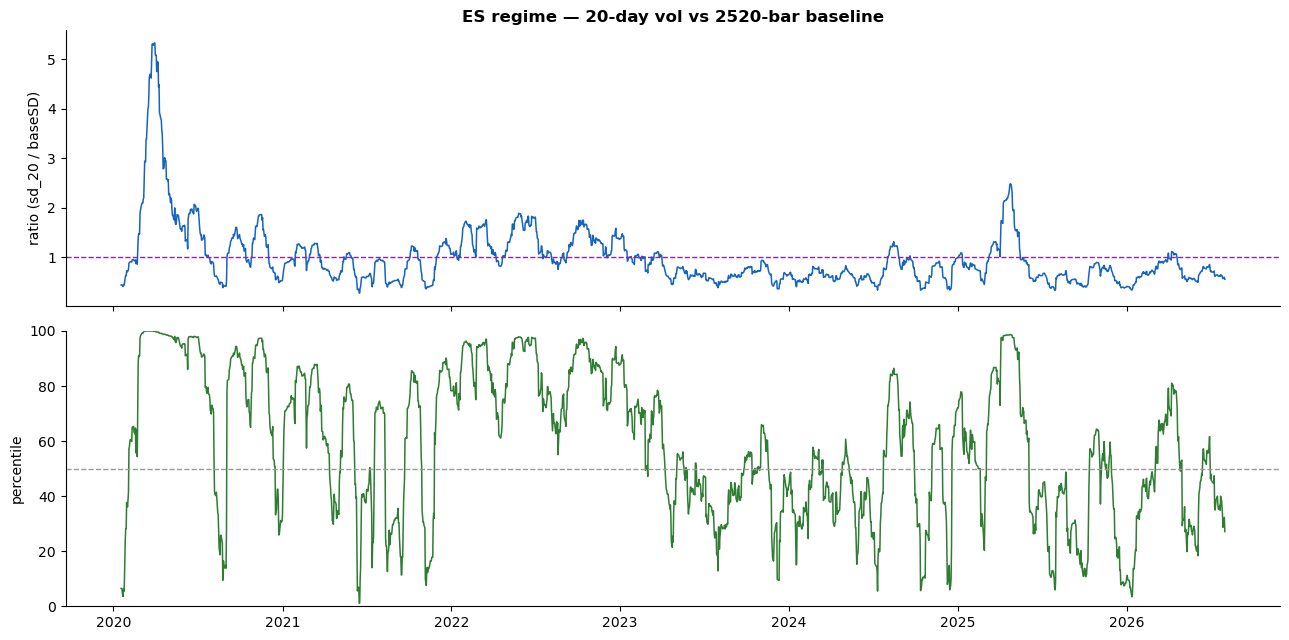

In [11]:
# ═══════════════════════════════════════════════════════════════════════
# OPTIONAL  — the regime through time (ratio + percentile) for one lookback
# ═══════════════════════════════════════════════════════════════════════
import matplotlib.pyplot as plt
%matplotlib inline

L = LOOKBACKS[1]      # which lookback to plot
fig, (a1, a2) = plt.subplots(2, 1, figsize=(13, 6.5), sharex=True)
a1.plot(regime.index, regime[f'ratio_{L}'], color='#1565c0', lw=1.1)
a1.axhline(1.0, color='#8e24aa', ls='--', lw=1)
a1.set_ylabel(f'ratio (sd_{L} / baseSD)')
a1.set_title(f'{SYMBOL} regime — {L}-day vol vs {regime.attrs["trail_len"]}-bar baseline',
             fontweight='bold')
a1.spines[['top', 'right']].set_visible(False)
a2.plot(regime.index, regime[f'pctile_{L}'], color='#2e7d32', lw=1.1)
a2.axhline(50, color='#999', ls='--', lw=1)
a2.set_ylabel('percentile'); a2.set_ylim(0, 100)
a2.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

In [12]:
# ═══════════════════════════════════════════════════════════════════════
# The full daily series is in `regime` — every column, all history.
# e.g. the most recent rows of the L2 read:
# ═══════════════════════════════════════════════════════════════════════
L = LOOKBACKS[1]
regime[['base_sd', f'sd_{L}', f'ratio_{L}', f'pctile_{L}',
        f'trend_{L}', f'state_{L}', f'compr_{L}', 'overall']].dropna().tail(10)

,base_sd,sd_20,ratio_20,pctile_20,trend_20,state_20,compr_20,overall
Datetime,,,,,,,,
2026-07-21 18:00:00,0.010279,0.006305,0.613430,34.880952,-0.032646,Compressed,HOLD,STABLE
2026-07-22 18:00:00,0.010283,0.006636,0.645351,40.000000,0.019602,Compressed,HOLD,STABLE
2026-07-23 18:00:00,0.010284,0.006494,0.631469,38.095238,0.015715,Compressed,HOLD,STABLE
2026-07-24 18:00:00,0.010284,0.006516,0.633596,38.452381,0.018052,Compressed,HOLD,STABLE
2026-07-26 18:00:00,0.010284,0.006168,0.599760,33.214286,-0.023999,Compressed,HOLD,STABLE
2026-07-27 18:00:00,0.010284,0.005817,0.565604,28.690476,-0.047826,Compressed,HOLD,STABLE
2026-07-28 18:00:00,0.010284,0.005901,0.573780,29.761905,-0.071570,Compressed,BUILD,COMPRESSING
2026-07-29 18:00:00,0.010284,0.006015,0.584858,30.992063,-0.046611,Compressed,HOLD,STABLE
2026-07-30 18:00:00,0.010284,0.006104,0.593582,32.261905,-0.040013,Compressed,HOLD,STABLE
